[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DilaraLiyanage/colombo-rainfall-simulator/blob/main/notebook/colombo-rainfall-simulator.ipynb)

# Colombo Rainfall Simulator

Historical precipitation preprocessing, exploratory analysis and calibration of occurrence and conditional rainfall intensity. Simulation and independent holdout evaluation remain pending.

## 1. Problem and question

How do rainfall occurrence patterns and intensity influence the probability of extreme rainfall events in Colombo? Historical summaries describe associations, not causal effects.

## 2. Model, assumptions and equations

For hourly accumulation $h_t$ ending at local timestamp $t$, daily precipitation is $R_d=\sum_{t:\operatorname{date}(t-1\mathrm{h})=d}h_t$. The wet indicator is $W_d=\mathbf{1}(R_d\geq0.1)$ and model rainfall is $R_d^*=R_d W_d$. Extreme events are $E_d=\mathbf{1}(R_d>q_{0.95,\mathrm{cal}})$, using all original calibration totals and linear quantile interpolation. The same threshold applies to the holdout. The approved baseline is a homogeneous first-order two-state chain and a lower-truncated Gamma wet-amount distribution. Calibration and alternative fits are implemented below; stochastic generation remains pending. Seasons follow Deoras et al. (2023), reference 7.

## 3. Implementation

Open-Meteo Historical Weather API, Best Match (user-supplied acquisition setting). The supplied acquisition URL is reported to request latitude 6.9355 and longitude 79.8487. Both CSV metadata records report returned latitude 6.924429 and longitude 79.90725, elevation 4 m. The full query and acquisition date are not available here; the relationship between the reported URL and these exact snapshots requires confirmation. Local timestamps are interpreted as exported, without conversion to UTC. Best Match may combine products; no exclusive ERA5/ERA5-Land claim. Data credits: https://open-meteo.com/en/license (CC BY 4.0); upstream Copernicus/ECMWF notices apply. See `data/README.md`.

In [1]:
# C01
import sys, subprocess, importlib.metadata, time, json, platform
RUN_START = time.perf_counter()
PINS = {'numpy': '2.3.5', 'pandas': '2.2.3', 'scipy': '1.17.0', 'matplotlib': '3.10.8'}
missing = []
for package, version in PINS.items():
    try:
        if importlib.metadata.version(package) != version: missing.append(f"{package}=={version}")
    except importlib.metadata.PackageNotFoundError: missing.append(f"{package}=={version}")
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *[f"{k}=={v}" for k,v in PINS.items()]])
print("Python", platform.python_version(), "| pinned packages", PINS)
from pathlib import Path
import os, io, hashlib, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib, scipy
assert {"numpy":np.__version__, "pandas":pd.__version__, "scipy":scipy.__version__, "matplotlib":matplotlib.__version__} == PINS, "Loaded scientific versions differ from installed pins"
from IPython.display import display
SEED = 42
rng = np.random.default_rng(SEED)
# Future independent replications: call once per experiment, then allocate one stream per replicate.
def replication_streams(n):
    return [np.random.default_rng(child) for child in np.random.SeedSequence(SEED).spawn(n)]
QUANTILES = (.95, .99)
FIT_QUANTILES = (.90, .95, .99)
RTOL, ATOL = 1e-8, 1e-9
OPT_SETTINGS = {"ftol":1e-13,"gtol":1e-6,"maxiter":1000}
OPT_BOUNDS = (-10,12)
DPI = 300
FIGURE_DATA = {}
WET = 0.1
START, END = pd.Timestamp('2001-01-01'), pd.Timestamp('2025-12-31')
CAL_END = pd.Timestamp('2020-12-31')
BASE = 'https://raw.githubusercontent.com/DilaraLiyanage/colombo-rainfall-simulator/main/data/raw/'
# RAINFALL_DATA_DIR optionally points directly to the raw snapshot directory.
DATA_DIR = Path(os.environ.get('RAINFALL_DATA_DIR', 'data/raw'))
OUTPUT = Path(os.environ.get('RAINFALL_OUTPUT_DIR', '.'))
RAW_DIR = OUTPUT/'data'/'raw'
PROCESSED_DIR = OUTPUT/'data'/'processed'
RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
(OUTPUT/'figures').mkdir(parents=True, exist_ok=True)
print('Runtime:', 'Colab' if 'COLAB_RELEASE_TAG' in os.environ else 'local Python', '| pandas', pd.__version__, '| numpy', np.__version__)

Python 3.13.18 | pinned packages {'numpy': '2.3.5', 'pandas': '2.2.3', 'scipy': '1.17.0', 'matplotlib': '3.10.8'}
Runtime: Colab | pandas 2.2.3 | numpy 2.3.5


In [2]:
# C02
def load_export(kind):
    name = f'open-meteo-6.92N79.91E4m-{kind}.csv'
    # Prefer frozen public snapshot; fall back to existing local file, not interactive upload.
    try:
        # Explicit local override supports offline, reproducible execution.
        if 'RAINFALL_DATA_DIR' in os.environ:
            raise OSError('Explicit local snapshot directory selected')
        with urllib.request.urlopen(BASE + name, timeout=15) as response:
            raw = response.read()
        source = 'GitHub raw'
    except (OSError, ValueError):
        candidates = [DATA_DIR/name, RAW_DIR/name, Path('../data/raw')/name]
        path = next((x for x in candidates if x.is_file()), None)
        if path is None:
            raise FileNotFoundError(f'Place {name} in data/raw/ or set RAINFALL_DATA_DIR; public snapshot not available.')
        raw = path.read_bytes()
        source = 'local snapshot'
    expected_sha256 = {
        'hourly': 'd14a8d9739fdf5337172a82b28226fa446af02919a92dfbef8cc52701d5d9601',
        'daily': 'dc672e756178597e04c779eddee2003ae4312003578ea85d0f1730aa5c5fdcda',
    }
    assert hashlib.sha256(raw).hexdigest() == expected_sha256[kind], f'Snapshot checksum mismatch: {name}'
    meta = pd.read_csv(io.BytesIO(raw), nrows=1)
    frame = pd.read_csv(io.BytesIO(raw), skiprows=3)
    print(kind, source, 'SHA256:', hashlib.sha256(raw).hexdigest(), 'rows:', len(frame))
    display(meta)
    print(frame.columns.tolist())
    return frame, meta
hourly, hm = load_export('hourly')
daily_ref, dm = load_export('daily')
assert hm.equals(dm)
assert hm.loc[0,'timezone'] == 'Asia/Colombo' and hm.loc[0,'utc_offset_seconds'] == 19800
hourly['time'] = pd.to_datetime(hourly['time'], errors='raise')
daily_ref['time'] = pd.to_datetime(daily_ref['time'], errors='raise')
h = hourly.set_index('time')['precipitation (mm)']
ref = daily_ref.set_index('time')['precipitation_sum (mm)']
assert h.index.is_unique and ref.index.is_unique
assert h.index.is_monotonic_increasing and ref.index.is_monotonic_increasing
assert np.isfinite(h).all() and np.isfinite(ref).all()
assert (h>=0).all() and (ref>=0).all()

hourly GitHub raw SHA256: d14a8d9739fdf5337172a82b28226fa446af02919a92dfbef8cc52701d5d9601 rows: 219168


,latitude,longitude,elevation,utc_offset_seconds,timezone,timezone_abbreviation
0,6.924429,79.90725,4.0,19800,Asia/Colombo,GMT+5:30


['time', 'precipitation (mm)']
daily GitHub raw SHA256: dc672e756178597e04c779eddee2003ae4312003578ea85d0f1730aa5c5fdcda rows: 9132


,latitude,longitude,elevation,utc_offset_seconds,timezone,timezone_abbreviation
0,6.924429,79.90725,4.0,19800,Asia/Colombo,GMT+5:30


['time', 'precipitation_sum (mm)', 'precipitation_hours (h)']


In [3]:
# C03
expected_hours = pd.date_range(START + pd.Timedelta(hours=1), END + pd.Timedelta(days=1), freq='h')
selected = h.loc[expected_hours[0]:expected_hours[-1]]
assert len(selected)==219144 and selected.index.equals(expected_hours)
assert selected.notna().all() and (selected>=0).all()
def aggregate(series, corrected=True):
    dates = (series.index - pd.Timedelta(hours=int(corrected))).normalize()
    grouped = series.groupby(dates)
    return grouped.sum(), grouped.size()
rain, counts = aggregate(selected)
assert len(rain)==9131 and rain.index.equals(pd.date_range(START, END))
assert (counts==24).all()
assert np.isclose(selected.sum(), rain.sum(), rtol=1e-12, atol=1e-8)
print('PASS: hourly continuity, uniqueness, finite nonnegative values, daily coverage, 24/day, mass conservation')
print('Hourly records:', len(selected), 'Daily records:', len(rain), 'Total mm:', rain.sum())

PASS: hourly continuity, uniqueness, finite nonnegative values, daily coverage, 24/day, mass conservation
Hourly records: 219144 Daily records: 9131 Total mm: 68017.7


In [4]:
# C04
# Both methods use complete dates, with the extra leading hour available in the original export.
correct, nc = aggregate(h, True)
uncorrect, nu = aggregate(h, False)
comparison = pd.concat([correct.rename('corrected'), uncorrect.rename('uncorrected'), ref.rename('reference'), nc.rename('n_corrected'), nu.rename('n_uncorrected')], axis=1).loc[START:END]
comparison = comparison.loc[(comparison.n_corrected==24)&(comparison.n_uncorrected==24)].dropna()
assert len(comparison)==9131
TOL = 0.1  # mm; material means strictly greater, ignoring binary roundoff
rows = []
for col in ['corrected','uncorrected']:
    err = comparison[col]-comparison.reference
    rows.append({'method':col,'days':len(err),'MAE_mm':err.abs().mean(),'RMSE_mm':np.sqrt((err**2).mean()),'max_abs_mm':err.abs().max(),'material_days':int((err.abs()>TOL+1e-9).sum()),'mean_bias_mm':err.mean()})
metrics = pd.DataFrame(rows).set_index('method')
display(metrics)
# Difference between methods must equal next midnight minus current midnight.
mid = h.reindex(comparison.index).to_numpy()
next_mid = h.reindex(comparison.index+pd.Timedelta(days=1)).to_numpy()
np.testing.assert_allclose(comparison.corrected-comparison.uncorrected,next_mid-mid,atol=1e-9,rtol=1e-12)
print('Largest corrected residuals:')
display(comparison.assign(abs_error=(comparison.corrected-comparison.reference).abs()).nlargest(5,'abs_error'))
print('Corrected signed residual by year (mm/day):')
display((comparison.corrected-comparison.reference).groupby(comparison.index.year).mean().round(4))

,days,MAE_mm,RMSE_mm,max_abs_mm,material_days,mean_bias_mm
method,,,,,,
corrected,9131,4.060672e-01,1.303786e+00,2.200000e+01,3353,2.101046e-17
uncorrected,9131,1.178677e-16,5.944685e-16,1.421085e-14,0,2.898666e-17


Largest corrected residuals:


,corrected,uncorrected,reference,n_corrected,n_uncorrected,abs_error
time,,,,,,
2006-11-06,56.6,34.6,34.6,24,24.0,22.0
2006-11-07,89.7,111.7,111.7,24,24.0,22.0
2006-11-16,44.8,63.0,63.0,24,24.0,18.2
2006-11-15,32.9,14.7,14.7,24,24.0,18.2
2021-03-27,53.1,35.0,35.0,24,24.0,18.1


Corrected signed residual by year (mm/day):


,0
time,
2001,0.0000
2002,-0.0000
2003,0.0000
2004,0.0000
2005,0.0000
2006,-0.0000
2007,0.0000
2008,-0.0000
2009,0.0000


In [5]:
# C05
df = rain.rename('rainfall_mm').rename_axis('date').reset_index()
# The exports have centesimal precision; round only binary summation noise, not physical values.
df['rainfall_mm'] = df.rainfall_mm.round(10)
df['is_wet'] = df.rainfall_mm >= WET
df['model_rainfall_mm'] = df.rainfall_mm.where(df.is_wet,0.0)
df['year'] = df.date.dt.year
df['month'] = df.date.dt.month
season_map = {1:'NEM',2:'NEM',3:'FIM',4:'FIM',5:'SWM',6:'SWM',7:'SWM',8:'SWM',9:'SWM',10:'SIM',11:'SIM',12:'NEM'}
df['season'] = df.month.map(season_map)
df['split'] = np.where(df.date<=CAL_END,'calibration','evaluation')
cal_mask = df.split.eq('calibration')
q95,q99 = df.loc[cal_mask,'rainfall_mm'].quantile(list(QUANTILES),interpolation='linear').to_numpy()
df['is_extreme'] = df.rainfall_mm > q95
columns = ['date','rainfall_mm','model_rainfall_mm','is_wet','year','month','season','is_extreme','split']
df = df[columns]
cal = df.loc[cal_mask].copy(); evaluation = df.loc[~cal_mask].copy()
print(f'Calibration q95={q95:.6f} mm; q99={q99:.6f} mm')
for label, part in [('all',df),('calibration',cal),('evaluation',evaluation)]:
    loss = (part.rainfall_mm-part.model_rainfall_mm).sum()
    print(label, 'trace loss mm:',round(loss,6),'percent:',100*loss/part.rainfall_mm.sum())
for name, part in [('processed_daily',df),('calibration_daily',cal),('evaluation_daily',evaluation)]:
    part.to_csv(PROCESSED_DIR/f'{name}.csv',index=False,date_format='%Y-%m-%d')

Calibration q95=25.200000 mm; q99=46.296000 mm
all trace loss mm: 0.0 percent: 0.0
calibration trace loss mm: 0.0 percent: 0.0
evaluation trace loss mm: 0.0 percent: 0.0


## 4. Verification

Executable preprocessing checks are distinct from future scientific simulation verification. Missing hours are never filled with zero. Midnight belongs to the previous accumulation day; leap dates are retained.

In [6]:
# C06
toy = pd.Series([2.,3.,5.],index=pd.to_datetime(['2020-02-29 23:00','2020-03-01 00:00','2020-03-01 01:00']))
toy_daily,_ = aggregate(toy)
assert toy_daily.loc['2020-02-29']==5 and toy_daily.loc['2020-03-01']==5
assert len(cal)==7305 and len(evaluation)==1826
assert cal.date.is_monotonic_increasing and evaluation.date.is_monotonic_increasing
assert not set(cal.date)&set(evaluation.date)
assert cal.date.iloc[0]==START and cal.date.iloc[-1]==CAL_END
assert evaluation.date.iloc[0]==pd.Timestamp('2021-01-01') and evaluation.date.iloc[-1]==END
assert len(df[df.date.dt.strftime('%m-%d')=='02-29'])==6
assert (df.is_extreme==(df.rainfall_mm>q95)).all()
assert (df.is_wet==(df.rainfall_mm>=WET)).all()
assert (df.loc[~df.is_wet,'model_rainfall_mm']==0).all()
assert q95==cal.rainfall_mm.quantile(.95)
print('PASS: midnight/leap example, six leap days, chronological disjoint splits, fixed calibration threshold and wet classification')
display(toy_daily)

PASS: midnight/leap example, six leap days, chronological disjoint splits, fixed calibration threshold and wet classification


,0
2020-02-29,5.0
2020-03-01,5.0


## 5. Experiments and results

Historical exploratory summaries only. Holdout figures and statistics are descriptive and must not be used to choose fitted parameters or thresholds. Monthly climatology uses mean monthly totals across years, not mean daily precipitation.

In [7]:
# C07
def describe(part):
    x=part.rainfall_mm
    return pd.Series({'days':len(part),'total_mm':x.sum(),'mean_mm_day':x.mean(),'std_mm_day':x.std(),'median_mm':x.median(),'max_mm':x.max(),'wet_days':part.is_wet.sum(),'wet_frequency':part.is_wet.mean(),'mean_wet_mm':part.loc[part.is_wet,'rainfall_mm'].mean(),'extreme_days':part.is_extreme.sum(),'extreme_frequency':part.is_extreme.mean()})
summary=pd.DataFrame({'calibration':describe(cal),'evaluation (historical)':describe(evaluation)})
display(summary)
print('Calibration seasonal summaries:')
display(cal.groupby('season').apply(describe, include_groups=False))
summary.to_csv(PROCESSED_DIR/'summary.csv')
metrics.to_csv(PROCESSED_DIR/'aggregation_metrics.csv')

,calibration,evaluation (historical)
days,7305.000000,1826.000000
total_mm,52521.100000,15496.600000
mean_mm_day,7.189747,8.486637
std_mm_day,10.384421,11.759587
median_mm,3.600000,4.200000
max_mm,240.200000,204.600000
wet_days,6283.000000,1684.000000
wet_frequency,0.860096,0.922234
mean_wet_mm,8.359239,9.202257
extreme_days,365.000000,149.000000


Calibration seasonal summaries:


,days,total_mm,mean_mm_day,std_mm_day,median_mm,max_mm,wet_days,wet_frequency,mean_wet_mm,extreme_days,extreme_frequency
season,,,,,,,,,,,
FIM,1220.0,6333.6,5.191475,8.121758,2.3,81.4,1100.0,0.901639,5.757818,38.0,0.031148
NEM,1805.0,6080.9,3.368920,7.604891,0.3,97.4,1028.0,0.569529,5.915272,44.0,0.024377
SIM,1220.0,14456.9,11.849918,14.422237,7.7,133.0,1135.0,0.930328,12.737357,150.0,0.122951
SWM,3060.0,25649.7,8.382255,9.690734,5.6,240.2,3020.0,0.986928,8.493278,133.0,0.043464


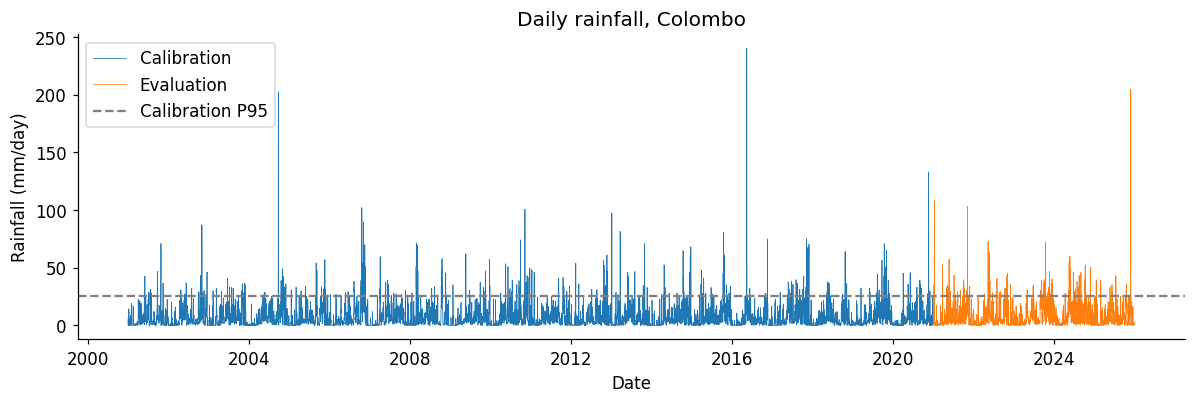

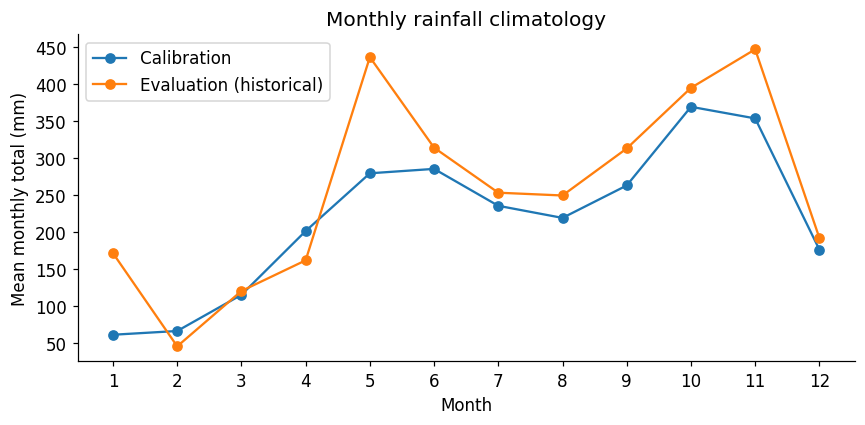

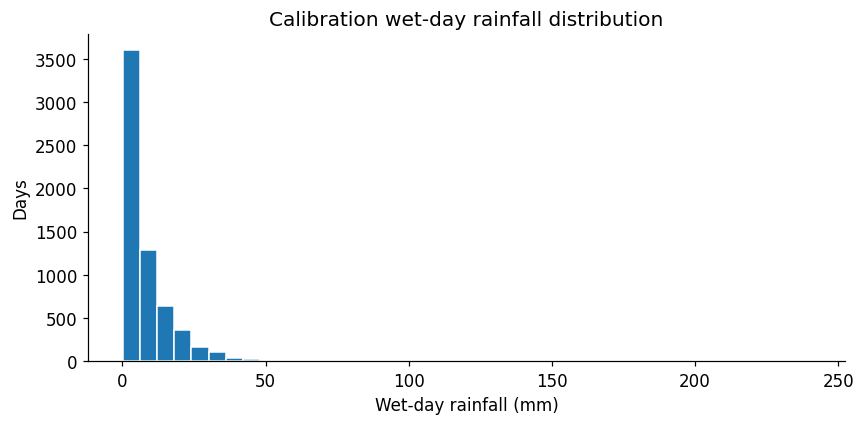

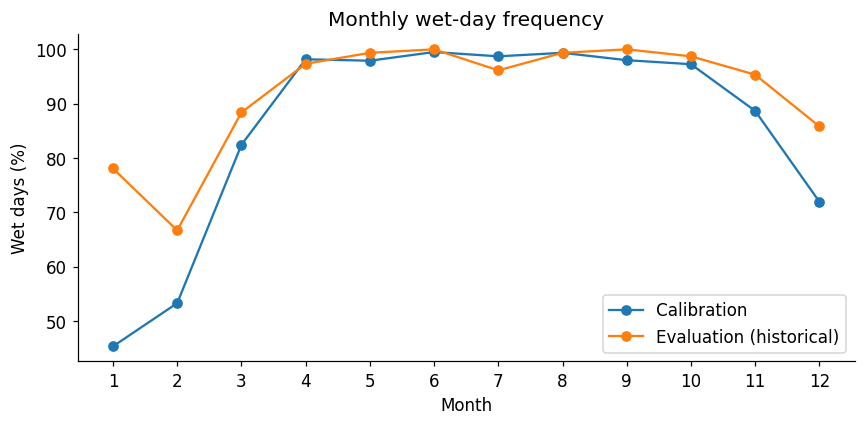

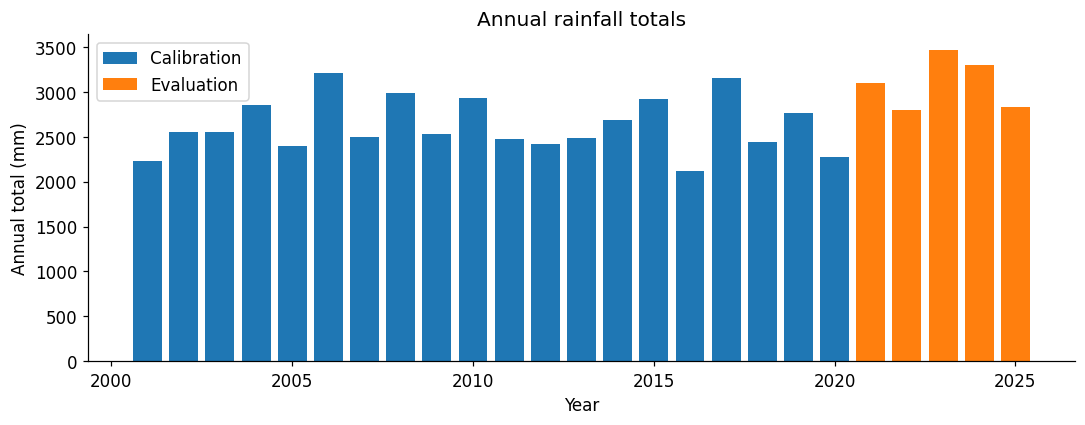

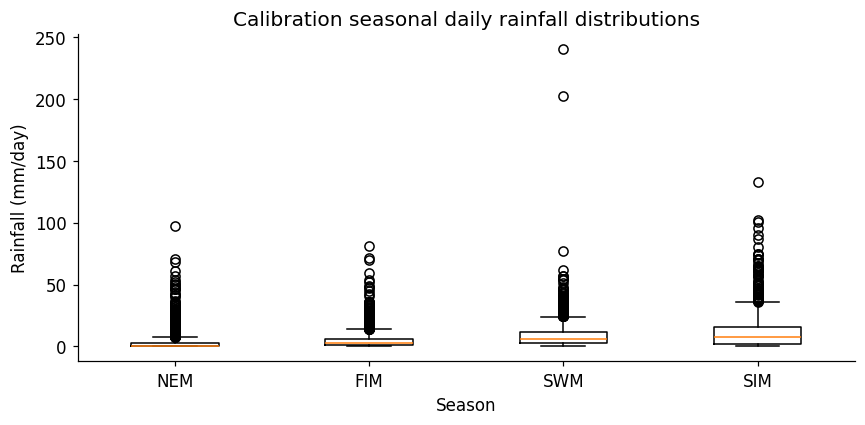

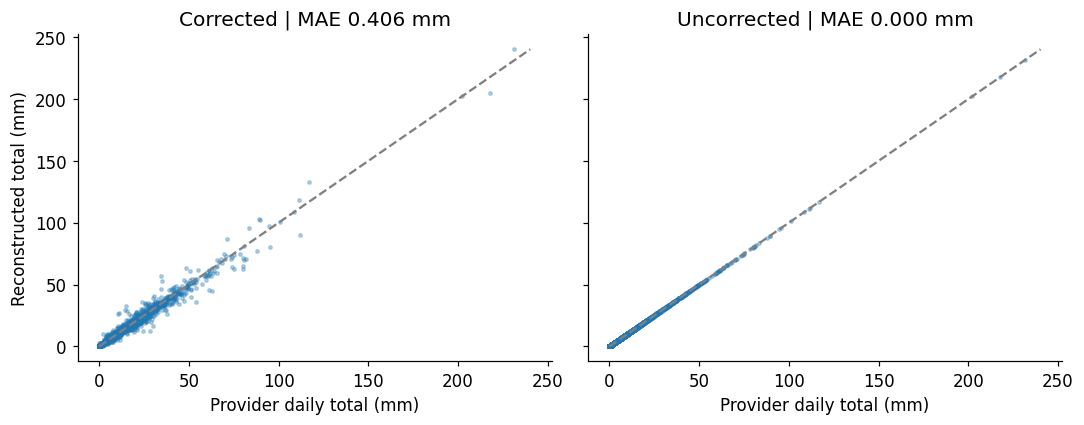

In [8]:
# C08
plt.style.use('default')
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':110})
def finish(fig, name):
    # Capture plotted numerical primitives, independent of raster rendering.
    payload=[]
    for ax in fig.axes:
        def arr(v):
            return np.asarray(v).tolist()
        payload.append({'lines':[[arr(l.get_xdata(orig=False)),arr(l.get_ydata(orig=False))] for l in ax.lines],
                        'images':[arr(im.get_array()) for im in ax.images],
                        'collections':[arr(col.get_offsets()) for col in ax.collections],
                        'rectangles':[[patch.get_x(),patch.get_y(),patch.get_width(),patch.get_height()] for patch in ax.patches if hasattr(patch,'get_width')],
                        'paths':[arr(patch.get_path().vertices) for patch in ax.patches if not hasattr(patch,'get_width')]})
    FIGURE_DATA[name]=payload
    fig.tight_layout(); fig.savefig(OUTPUT/'figures'/f'{name}.png',dpi=DPI,bbox_inches='tight'); plt.show(); plt.close(fig)
fig,ax=plt.subplots(figsize=(11,3.8)); ax.plot(cal.date,cal.rainfall_mm,lw=.5,label='Calibration'); ax.plot(evaluation.date,evaluation.rainfall_mm,lw=.5,label='Evaluation'); ax.axhline(q95,ls='--',color='gray',label='Calibration P95'); ax.set(ylabel='Rainfall (mm/day)',xlabel='Date',title='Daily rainfall, Colombo'); ax.legend(); finish(fig,'F01_daily_rainfall')
fig,ax=plt.subplots(figsize=(8,4));
for part,label in [(cal,'Calibration'),(evaluation,'Evaluation (historical)')]:
    monthly=part.groupby(['year','month']).rainfall_mm.sum().groupby('month').mean(); ax.plot(monthly.index,monthly.values,marker='o',label=label)
ax.set(xticks=range(1,13),xlabel='Month',ylabel='Mean monthly total (mm)',title='Monthly rainfall climatology'); ax.legend(); finish(fig,'F02_monthly_climatology')
fig,ax=plt.subplots(figsize=(8,4)); ax.hist(cal.loc[cal.is_wet,'rainfall_mm'],bins=40,edgecolor='white'); ax.set(xlabel='Wet-day rainfall (mm)',ylabel='Days',title='Calibration wet-day rainfall distribution'); finish(fig,'F03_wet_day_histogram')
fig,ax=plt.subplots(figsize=(8,4));
for part,label in [(cal,'Calibration'),(evaluation,'Evaluation (historical)')]:
    s=part.groupby('month').is_wet.mean()*100; ax.plot(s.index,s.values,marker='o',label=label)
ax.set(xticks=range(1,13),xlabel='Month',ylabel='Wet days (%)',title='Monthly wet-day frequency'); ax.legend(); finish(fig,'F04_monthly_wet_frequency')
fig,ax=plt.subplots(figsize=(10,4));
for part,label in [(cal,'Calibration'),(evaluation,'Evaluation')]:
    s=part.groupby('year').rainfall_mm.sum(); ax.bar(s.index,s.values,label=label)
ax.set(xlabel='Year',ylabel='Annual total (mm)',title='Annual rainfall totals'); ax.legend(); finish(fig,'F05_annual_rainfall')
fig,ax=plt.subplots(figsize=(8,4)); seasons=['NEM','FIM','SWM','SIM']; ax.boxplot([cal.loc[cal.season==s,'rainfall_mm'] for s in seasons]); ax.set(xticks=range(1,5),xticklabels=seasons,ylabel='Rainfall (mm/day)',xlabel='Season',title='Calibration seasonal daily rainfall distributions'); finish(fig,'F06_seasonal_distributions')
fig,axs=plt.subplots(1,2,figsize=(10,4),sharex=True,sharey=True); limit=comparison[['reference','corrected','uncorrected']].max().max();
for ax,col in zip(axs,['corrected','uncorrected']):
    ax.scatter(comparison.reference,comparison[col],s=5,alpha=.3); ax.plot([0,limit],[0,limit],ls='--',color='gray'); ax.set(xlabel='Provider daily total (mm)',title=col.capitalize()+f" | MAE {metrics.loc[col,'MAE_mm']:.3f} mm")
axs[0].set_ylabel('Reconstructed total (mm)'); finish(fig,'F07_daily_aggregation_comparison')

### Calibration of rainfall occurrence
All fits below use only `cal`, the contiguous 2001–2020 record. For states 0 (dry) and 1 (wet), $\hat p_{ij}=n_{ij}/\sum_j n_{ij}$. The stationary distribution satisfies $\pi P=\pi$, with $\pi_1=p_{01}/(p_{01}+p_{10})$. Spell lengths under a homogeneous chain have geometric distributions on positive integers: $P(L_i=l)=p_{i,1-i}p_{ii}^{l-1}$ and $E[L_i]=1/p_{i,1-i}$. Exclude boundary-censored runs from empirical spell summaries. For BIC use identical 7,304 destination observations and conditional likelihoods, with 1 independent parameter for order zero and 2 for order one. Lower BIC is preferred.

In [9]:
# C09
from scipy import stats, optimize, integrate
from scipy.special import xlogy
assert len(cal)==7305 and cal.date.min()==pd.Timestamp('2001-01-01') and cal.date.max()==CAL_END
assert cal.date.diff().iloc[1:].eq(pd.Timedelta(days=1)).all()
assert np.isclose(q95,25.2,rtol=RTOL,atol=ATOL) and np.isclose(q99,46.296,rtol=RTOL,atol=ATOL)
s = cal.is_wet.to_numpy(dtype=int)
pairs = pd.DataFrame({'previous':s[:-1],'current':s[1:],'season':cal.season.to_numpy()[1:]})
def transition_counts(pair):
    counts = np.zeros((2,2),dtype=int)
    np.add.at(counts,(pair.previous.to_numpy(),pair.current.to_numpy()),1)
    assert counts.sum()==len(pair) and (counts.sum(axis=1)>0).all()
    matrix=counts/counts.sum(axis=1,keepdims=True)
    assert np.all((matrix>=0)&(matrix<=1)) and np.allclose(matrix.sum(axis=1),1)
    return counts,matrix
N,P=transition_counts(pairs)
assert N.sum()==7304
pi=np.array([P[1,0],P[0,1]])/(P[0,1]+P[1,0])
assert np.all(pi>=0) and np.isclose(pi.sum(),1) and np.allclose(pi@P,pi)
ll1=xlogy(N,P).sum(); dest=N.sum(axis=0); ll0=xlogy(dest,dest/dest.sum()).sum()
occurrence_bic=pd.DataFrame({'order':[0,1],'log_likelihood':[ll0,ll1],'parameters':[1,2]})
occurrence_bic['BIC']=-2*occurrence_bic.log_likelihood+occurrence_bic.parameters*np.log(len(pairs))
transition_table=pd.DataFrame([{'from_state':i,'to_state':j,'count':N[i,j],'probability':P[i,j]} for i in range(2) for j in range(2)])
transition_table.to_csv(PROCESSED_DIR/'markov_transitions.csv',index=False)
occurrence_bic.to_csv(PROCESSED_DIR/'occurrence_bic.csv',index=False)
display(transition_table,occurrence_bic)
print('Stationary dry/wet:',pi,'Empirical wet frequency:',s.mean())
print('Transition and stationary assertions passed.')

,from_state,to_state,count,probability
0,0,0,670,0.655577
1,0,1,352,0.344423
2,1,0,352,0.056033
3,1,1,5930,0.943967


,order,log_likelihood,parameters,BIC
0,0,-2956.836554,1,5922.569286
1,1,-2014.438536,2,4046.669426


Stationary dry/wet: [0.13992333 0.86007667] Empirical wet frequency: 0.8600958247775496
Transition and stationary assertions passed.


In [10]:
# C10
# First and last runs may be censored; retain only complete interior spells.
boundaries=np.r_[0,np.flatnonzero(np.diff(s))+1,len(s)]
lengths=np.diff(boundaries); states=s[boundaries[:-1]]
assert lengths.sum()==len(s)
spells={i:lengths[1:-1][states[1:-1]==i] for i in (0,1)}
spell_summary=pd.DataFrame([{'state':i,'complete_spells':len(v),'empirical_mean_days':v.mean(),'median_days':np.median(v),'max_days':v.max(),'p95_days':np.quantile(v,.95),'theoretical_mean_days':1/P[i,1-i]} for i,v in spells.items()])
spell_summary.to_csv(PROCESSED_DIR/'spell_statistics.csv',index=False)
display(spell_summary)
print('Excluded endpoint runs:',lengths[[0,-1]])

,state,complete_spells,empirical_mean_days,median_days,max_days,p95_days,theoretical_mean_days
0,0,352,2.903409,2.0,18,10.0,2.903409
1,1,351,17.871795,4.0,245,106.5,17.846591


Excluded endpoint runs: [4 6]


### Lower-truncated intensity likelihood
For a parent density $f_\theta$ with CDF $F_\theta$, the wet-day density is $g_\theta(x)=f_\theta(x)/[1-F_\theta(\tau)]$ for $x\geq\tau=0.1$, and zero otherwise. Thus $\ell(\theta)=\sum_i\log f_\theta(x_i)-n\log\bar F_\theta(\tau)$. Use zero parent location, positive shape/scale via log parameters and survival functions for stable tail calculations. Exponential has one parameter, Gamma and log-normal two. Quantiles use the parent inverse survival function at $(1-u)\bar F(\tau)$. The Gamma conditional mean is $\alpha\beta\bar F_{\alpha+1,\beta}(\tau)/\bar F_{\alpha,\beta}(\tau)$. The exponential conditional mean is $\tau+\beta$; the log-normal conditional mean is $e^{\mu+\sigma^2/2}\Phi((\mu+\sigma^2-\log\tau)/\sigma)/\bar F(\tau)$. Fit with multiple deterministic starts; AIC/BIC are relative descriptive criteria, not absolute fit tests. Wet-day dependence and rounded data limit the interpretation of independent continuous likelihoods.

In [11]:
# C11
x=cal.loc[cal.is_wet,'rainfall_mm'].to_numpy()
assert len(x)==s.sum() and np.all(x>=WET)
def parent(name,z):
    a=np.exp(z)
    if name=='Gamma': return stats.gamma(a[0],loc=0,scale=a[1])
    if name=='Exponential': return stats.expon(loc=0,scale=a[0])
    if name=='Log-normal': return stats.lognorm(a[0],loc=0,scale=a[1])
    raise ValueError(name)
def fit_truncated(name,values):
    assert np.all(values>=WET)
    if name=='Gamma': init=np.log(stats.gamma.fit(values,floc=0)[::2])
    elif name=='Exponential': init=np.log([values.mean()-WET])
    else: init=np.log(stats.lognorm.fit(values,floc=0)[::2])
    def objective(z):
        d=parent(name,z); v=-(d.logpdf(values).sum()-len(values)*d.logsf(WET))
        return v if np.isfinite(v) else 1e100
    starts=[init,init+.4,init-.4]
    results=[optimize.minimize(objective,z,method='L-BFGS-B',bounds=[OPT_BOUNDS]*len(z),options=OPT_SETTINGS) for z in starts]
    good=[r for r in results if r.success and np.isfinite(r.fun)]
    assert good, name
    best=min(good,key=lambda r:r.fun)
    assert best.fun<=objective(init)+1e-6 and np.all(np.abs(best.x)<9.99)
    d=parent(name,best.x); norm=d.sf(WET)
    assert norm>0 and np.isclose(integrate.quad(lambda t:d.pdf(t)/norm,WET,np.inf)[0],1,atol=1e-7)
    return d,best,results
names=['Gamma','Exponential','Log-normal']
fits={name:fit_truncated(name,x) for name in names}
def survival(d,t): return np.where(np.asarray(t)<WET,1.,d.sf(t)/d.sf(WET))
def quantile(d,u): return d.isf((1-np.asarray(u))*d.sf(WET))
def fit_row(name,fit,values):
    d,r,rs=fit; pars=np.exp(r.x); k=len(pars); ll=-r.fun
    return {'distribution':name,'n':len(values),'shape':pars[0] if k==2 else np.nan,'scale_mm':pars[-1],'log_likelihood':ll,'AIC':2*k-2*ll,'BIC':k*np.log(len(values))-2*ll,'converged':r.success,'successful_starts':sum(t.success for t in rs),'iterations':r.nit,'gradient_inf_norm':np.max(np.abs(r.jac)),'normalisation':d.sf(WET)}
fit_table=pd.DataFrame([fit_row(name,fit,x) for name,fit in fits.items()])
fit_table.to_csv(PROCESSED_DIR/'distribution_fits.csv',index=False)
display(fit_table)
print('All selected optimisations converged; truncated densities integrate to one.')

,distribution,n,shape,scale_mm,log_likelihood,AIC,BIC,converged,successful_starts,iterations,gradient_inf_norm,normalisation
0,Gamma,6283,0.708847,11.343818,-19389.890899,38783.781799,38797.273004,True,3,9,0.000364,0.961744
1,Exponential,6283,NaN,8.259239,-19548.501964,39099.003929,39105.749531,True,3,5,0.000000,0.987965
2,Log-normal,6283,1.352630,4.129066,-19702.582815,39409.165630,39422.656836,True,3,9,0.000728,0.997026


All selected optimisations converged; truncated densities integrate to one.


In [12]:
# C12
# Compare conditional wet-day quantiles and strict exceedance at fixed all-day thresholds.
qs=FIT_QUANTILES; thresholds=[q95,q99]
quantile_table=pd.DataFrame([{'distribution':name,'quantile':u,'observed_mm':np.quantile(x,u),'fitted_mm':quantile(fit[0],u),'error_mm':quantile(fit[0],u)-np.quantile(x,u)} for name,fit in fits.items() for u in qs])
tail_table=pd.DataFrame([{'distribution':name,'threshold_mm':t,'observed_wet_exceedance':np.mean(x>t),'fitted_wet_exceedance':float(survival(fit[0],t)),'error':float(survival(fit[0],t))-np.mean(x>t)} for name,fit in fits.items() for t in thresholds])
quantile_table.to_csv(PROCESSED_DIR/'distribution_quantiles.csv',index=False)
tail_table.to_csv(PROCESSED_DIR/'distribution_tail_errors.csv',index=False)
display(quantile_table,tail_table)

,distribution,quantile,observed_mm,fitted_mm,error_mm
0,Gamma,0.90,20.000,20.521050,0.521050
1,Gamma,0.95,26.800,27.651071,0.851071
2,Gamma,0.99,48.754,44.643744,-4.110256
3,Exponential,0.90,20.000,19.117601,-0.882399
4,Exponential,0.95,26.800,24.842470,-1.957530
5,Exponential,0.99,48.754,38.135202,-10.618798
6,Log-normal,0.90,20.000,23.425171,3.425171
7,Log-normal,0.95,26.800,38.278271,11.478271
8,Log-normal,0.99,48.754,96.182844,47.428844


,distribution,threshold_mm,observed_wet_exceedance,fitted_wet_exceedance,error
0,Gamma,25.200,0.058093,0.063347,0.005253
1,Gamma,46.296,0.011778,0.008569,-0.003209
2,Exponential,25.200,0.058093,0.047882,-0.010212
3,Exponential,46.296,0.011778,0.003723,-0.008055
4,Log-normal,25.200,0.058093,0.090842,0.032749
5,Log-normal,46.296,0.011778,0.037088,0.025310


### Analytical benchmarks and seasonal preparation
Under the stationary homogeneous chain and independent conditional wet-day amounts, $E[R]=\pi_1 E[X\mid X\geq\tau]$ and $P(R>u)=\pi_1\bar F_\theta(u)/\bar F_\theta(\tau)$ for $u\geq\tau$. These are deterministic targets, not simulated estimates. Seasonal counts classify each adjacent transition by the destination date, including transitions crossing season boundaries. No disjoint blocks are joined. A seasonal chain is time-inhomogeneous, so separate stationary probabilities are not a global stationary distribution.

In [13]:
# C13
from scipy.special import gammaincc
G=fits['Gamma'][0]; alpha=G.args[0]; beta=G.kwds['scale']
wet_mean=alpha*beta*gammaincc(alpha+1,WET/beta)/gammaincc(alpha,WET/beta)
quad_mean=integrate.quad(lambda t:t*G.pdf(t)/G.sf(WET),WET,np.inf)[0]
assert np.isclose(wet_mean,quad_mean,rtol=1e-8)
for t in thresholds:
    assert np.isclose(survival(G,t),integrate.quad(lambda v:G.pdf(v)/G.sf(WET),t,np.inf)[0],rtol=1e-8)
bench=pd.DataFrame([('stationary_wet_probability',pi[1],s.mean()),('mean_wet_mm',wet_mean,x.mean()),('expected_daily_mm',pi[1]*wet_mean,cal.model_rainfall_mm.mean()),('mean_wet_spell_days',1/P[1,0],spells[1].mean()),('mean_dry_spell_days',1/P[0,1],spells[0].mean()),('daily_P95_exceedance',pi[1]*survival(G,q95),np.mean(cal.rainfall_mm>q95)),('daily_P99_exceedance',pi[1]*survival(G,q99),np.mean(cal.rainfall_mm>q99))],columns=['metric','analytical','historical_calibration'])
bench.to_csv(PROCESSED_DIR/'analytical_benchmarks.csv',index=False)
display(bench)
print('Analytical mean and exceedances independently checked by quadrature.')

,metric,analytical,historical_calibration
0,stationary_wet_probability,0.860077,0.860096
1,mean_wet_mm,8.359239,8.359239
2,expected_daily_mm,7.189586,7.189747
3,mean_wet_spell_days,17.846591,17.871795
4,mean_dry_spell_days,2.903409,2.903409
5,daily_P95_exceedance,0.054483,0.049966
6,daily_P99_exceedance,0.007370,0.010130


Analytical mean and exceedances independently checked by quadrature.


In [14]:
# C14
seasons=['NEM','FIM','SWM','SIM']; seasonal_rows=[]; seasonal_counts=[]
for season in seasons:
    counts,matrix=transition_counts(pairs[pairs.season==season])
    values=cal.loc[cal.is_wet & cal.season.eq(season),'rainfall_mm'].to_numpy()
    fit=fit_truncated('Gamma',values)
    row=fit_row('Gamma',fit,values); row['season']=season
    for i in (0,1):
        for j in (0,1):
            row[f'n{i}{j}']=counts[i,j]; row[f'p{i}{j}']=matrix[i,j]
    seasonal_rows.append(row); seasonal_counts.append(counts)
assert np.array_equal(np.sum(seasonal_counts,axis=0),N)
seasonal=pd.DataFrame(seasonal_rows)
seasonal.to_csv(PROCESSED_DIR/'seasonal_parameters.csv',index=False)
display(seasonal)
print('Seasonal counts exactly partition the homogeneous counts; all fits converged.')

,distribution,n,shape,scale_mm,log_likelihood,AIC,BIC,converged,successful_starts,iterations,...,normalisation,season,n00,p00,n01,p01,n10,p10,n11,p11
0,Gamma,1028,0.258186,16.126726,-2612.187012,5228.374024,5238.244764,True,3,10,...,0.702860,NEM,566,0.727506,212,0.272494,211,0.205653,815,0.794347
1,Gamma,1100,0.470697,10.715368,-2905.691818,5815.383637,5825.389768,True,3,10,...,0.875282,FIM,54,0.428571,72,0.571429,66,0.060329,1028,0.939671
2,Gamma,3020,1.166920,7.233504,-9428.199965,18860.399930,18872.425954,True,3,9,...,0.993796,SWM,10,0.256410,29,0.743590,30,0.009930,2991,0.990070
3,Gamma,1135,0.795474,15.705930,-3999.702066,8003.404133,8013.472909,True,3,9,...,0.980800,SIM,40,0.506329,39,0.493671,45,0.039439,1096,0.960561


Seasonal counts exactly partition the homogeneous counts; all fits converged.


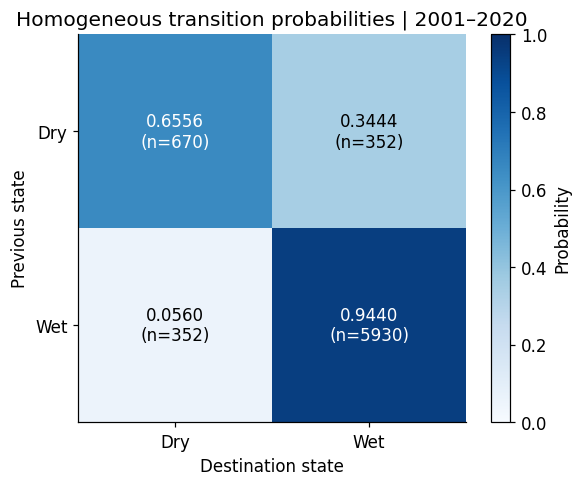

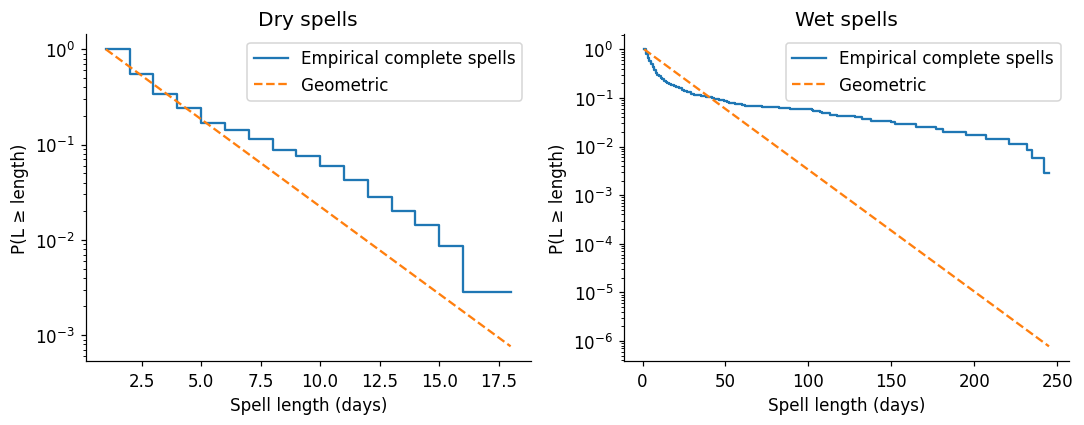

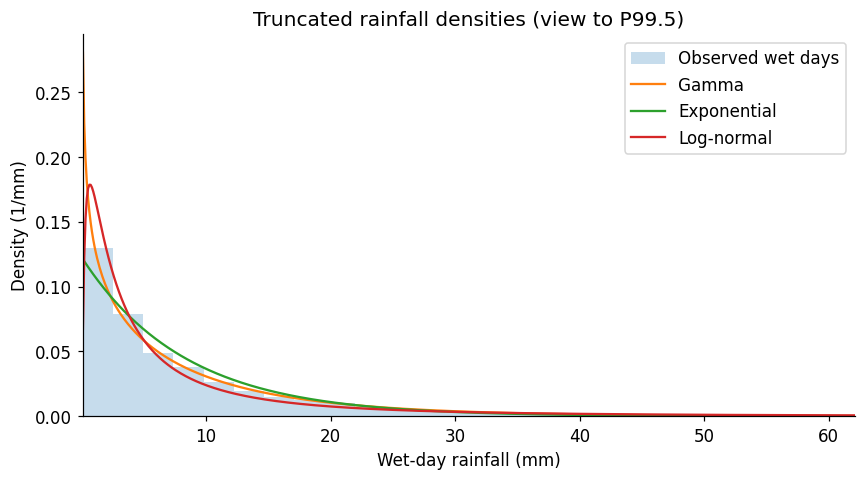

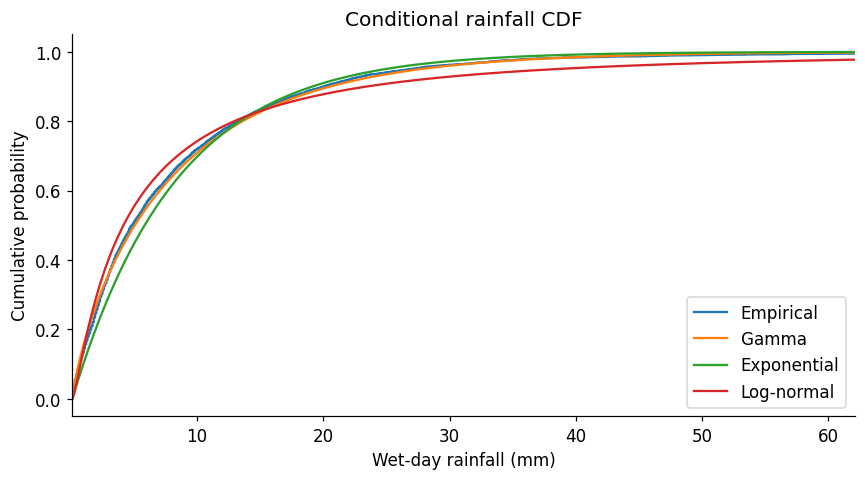

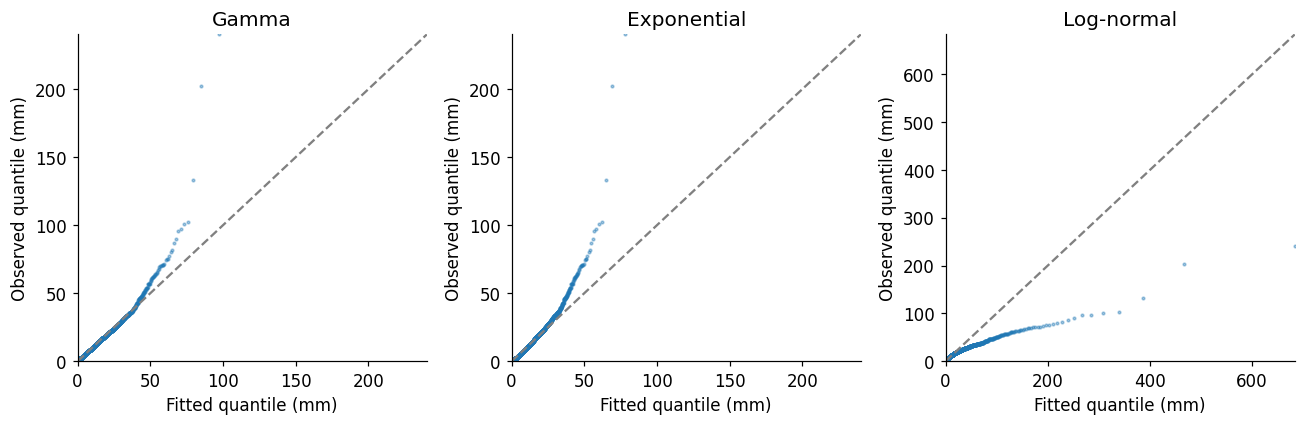

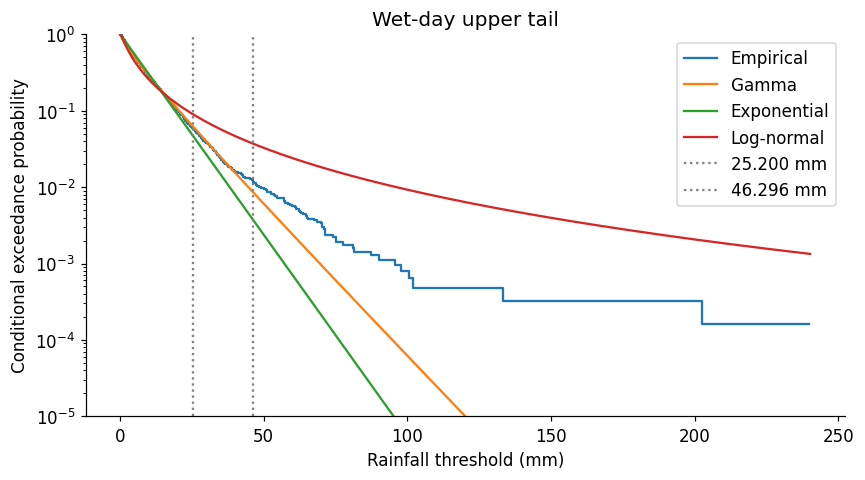

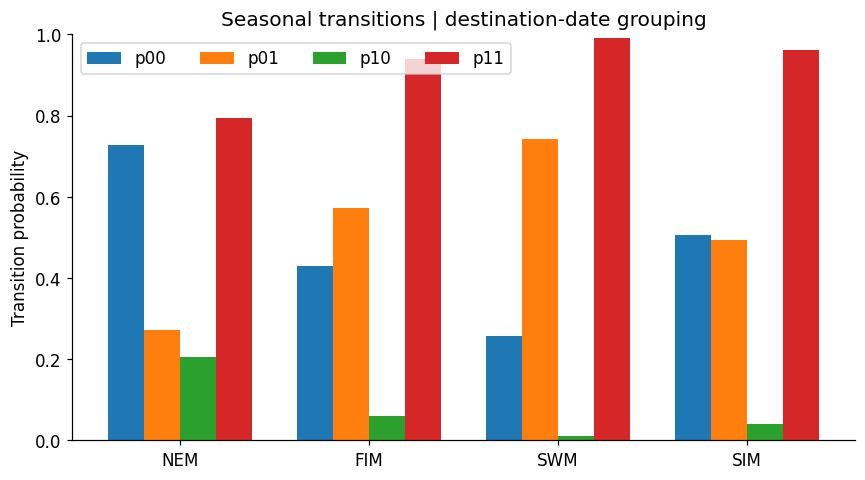

In [15]:
# C15
fig,ax=plt.subplots(figsize=(5.5,4.5)); im=ax.imshow(P,vmin=0,vmax=1,cmap='Blues')
for i in (0,1):
    for j in (0,1): ax.text(j,i,f'{P[i,j]:.4f}\n(n={N[i,j]})',ha='center',va='center',color='white' if P[i,j]>.5 else 'black')
ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['Dry','Wet'],yticklabels=['Dry','Wet'],xlabel='Destination state',ylabel='Previous state',title='Homogeneous transition probabilities | 2001–2020'); fig.colorbar(im,ax=ax,label='Probability'); finish(fig,'F08_transition_matrix')
fig,axes=plt.subplots(1,2,figsize=(10,4))
for i,ax in enumerate(axes):
    v=spells[i]; k=np.arange(1,max(v)+1); ax.step(k,[np.mean(v>=t) for t in k],where='post',label='Empirical complete spells'); ax.plot(k,stats.geom.sf(k-1,P[i,1-i]),label='Geometric',ls='--'); ax.set(yscale='log',xlabel='Spell length (days)',ylabel='P(L ≥ length)',title=['Dry spells','Wet spells'][i]); ax.legend()
finish(fig,'F09_spell_distributions')
grid=np.linspace(WET,np.quantile(x,.995),600)
fig,ax=plt.subplots(figsize=(8,4.5)); ax.hist(x,bins=np.linspace(WET,x.max(),100),density=True,alpha=.25,label='Observed wet days')
for name,(d,*_) in fits.items(): ax.plot(grid,d.pdf(grid)/d.sf(WET),label=name)
ax.set(xlim=(WET,grid[-1]),xlabel='Wet-day rainfall (mm)',ylabel='Density (1/mm)',title='Truncated rainfall densities (view to P99.5)'); ax.legend(); finish(fig,'F10_fitted_densities')
fig,ax=plt.subplots(figsize=(8,4.5)); sx=np.sort(x); ax.step(sx,np.arange(1,len(x)+1)/len(x),where='post',label='Empirical')
for name,(d,*_) in fits.items(): ax.plot(grid,1-survival(d,grid),label=name)
ax.set(xlim=(WET,grid[-1]),xlabel='Wet-day rainfall (mm)',ylabel='Cumulative probability',title='Conditional rainfall CDF'); ax.legend(); finish(fig,'F11_fitted_cdfs')
fig,axes=plt.subplots(1,3,figsize=(12,4)); u=(np.arange(1,len(x)+1)-.5)/len(x)
for ax,(name,(d,*_)) in zip(axes,fits.items()):
    theoretical=quantile(d,u); lim=max(sx.max(),theoretical.max()); ax.scatter(theoretical,sx,s=3,alpha=.4); ax.plot([0,lim],[0,lim],ls='--',color='gray'); ax.set(xlabel='Fitted quantile (mm)',ylabel='Observed quantile (mm)',title=name,xlim=(0,lim),ylim=(0,lim))
finish(fig,'F12_distribution_qq')
fig,ax=plt.subplots(figsize=(8,4.5)); tgrid=np.linspace(WET,x.max(),500); empirical=np.array([np.mean(x>t) for t in tgrid]); ax.step(tgrid[empirical>0],empirical[empirical>0],where='post',label='Empirical')
for name,(d,*_) in fits.items(): ax.plot(tgrid,survival(d,tgrid),label=name)
for t in thresholds: ax.axvline(t,ls=':',color='gray',label=f'{t:.3f} mm')
ax.set(yscale='log',ylim=(1e-5,1),xlabel='Rainfall threshold (mm)',ylabel='Conditional exceedance probability',title='Wet-day upper tail'); ax.legend(); finish(fig,'F13_upper_tail')
fig,ax=plt.subplots(figsize=(8,4.5)); pos=np.arange(4); width=.19
for k,key in enumerate(['p00','p01','p10','p11']): ax.bar(pos+(k-1.5)*width,seasonal[key],width,label=key)
ax.set(xticks=pos,xticklabels=seasons,ylim=(0,1),ylabel='Transition probability',title='Seasonal transitions | destination-date grouping'); ax.legend(ncol=4); finish(fig,'F14_seasonal_transitions')

### Calibration findings (local execution)
The first-order conditional BIC (4046.67) is lower than order zero (5922.57) by 1875.90. This is evidence of dependence, not proof that one-day memory is sufficient. Complete wet spells have median 4 days, mean 17.87 days and maximum 245 days; the geometric model has mean 17.85 days but does not reproduce the observed spread well. Seasonal heterogeneity can generate long persistence even if transitions are first order within each season. The SWM dry-origin row has only 39 transitions, so its estimate warrants particular caution.

Gamma gives the lowest AIC and BIC among the three candidates. Conditional wet-day P99 is underestimated (44.64 versus 48.754 mm); the log-normal overestimates it (96.18 mm). Gamma gives daily exceedance probabilities 5.4483% and 0.7370% at the fixed all-day P95 and P99, respectively, compared with historical 4.9966% and 1.0130%. This is a fitted-model discrepancy, not a simulation failure. Retain Gamma as approved and investigate tail adequacy before claiming reliable extremes. Fitted likelihoods use a continuous approximation to rounded rainfall values. No fitted-distribution p-values are treated as conclusive. Numerical checks passed locally; independent Colab and Monte Carlo verification are pending.

### Reproducibility inventory
All outputs are regenerated from checksum-validated raw inputs. The manifest identifies producing cells. Figure primitives are captured separately from PNGs because fonts, antialiasing and rasterisation can differ across platforms. SeedSequence child streams are reserved for future independent replications; no random simulation is run here.

In [16]:
# C16
# Output inventory is declarative; all listed scientific outputs are generated above.
manifest = pd.DataFrame([{'path': 'data/processed/processed_daily.csv', 'cell': 'C05', 'description': 'processed daily'}, {'path': 'data/processed/calibration_daily.csv', 'cell': 'C05', 'description': 'calibration daily'}, {'path': 'data/processed/evaluation_daily.csv', 'cell': 'C05', 'description': 'evaluation daily'}, {'path': 'data/processed/summary.csv', 'cell': 'C07', 'description': 'summary'}, {'path': 'data/processed/aggregation_metrics.csv', 'cell': 'C07', 'description': 'aggregation metrics'}, {'path': 'data/processed/markov_transitions.csv', 'cell': 'C09', 'description': 'markov transitions'}, {'path': 'data/processed/occurrence_bic.csv', 'cell': 'C09', 'description': 'occurrence bic'}, {'path': 'data/processed/spell_statistics.csv', 'cell': 'C10', 'description': 'spell statistics'}, {'path': 'data/processed/distribution_fits.csv', 'cell': 'C11', 'description': 'distribution fits'}, {'path': 'data/processed/distribution_quantiles.csv', 'cell': 'C12', 'description': 'distribution quantiles'}, {'path': 'data/processed/distribution_tail_errors.csv', 'cell': 'C12', 'description': 'distribution tail errors'}, {'path': 'data/processed/analytical_benchmarks.csv', 'cell': 'C13', 'description': 'analytical benchmarks'}, {'path': 'data/processed/seasonal_parameters.csv', 'cell': 'C14', 'description': 'seasonal parameters'}, {'path': 'data/processed/output_manifest.csv', 'cell': 'C16', 'description': 'output manifest'}, {'path': 'data/processed/runtime_versions.csv', 'cell': 'C16', 'description': 'runtime versions'}, {'path': 'figures/F01_daily_rainfall.png', 'cell': 'C08', 'description': 'daily rainfall'}, {'path': 'figures/F02_monthly_climatology.png', 'cell': 'C08', 'description': 'monthly climatology'}, {'path': 'figures/F03_wet_day_histogram.png', 'cell': 'C08', 'description': 'wet day histogram'}, {'path': 'figures/F04_monthly_wet_frequency.png', 'cell': 'C08', 'description': 'monthly wet frequency'}, {'path': 'figures/F05_annual_rainfall.png', 'cell': 'C08', 'description': 'annual rainfall'}, {'path': 'figures/F06_seasonal_distributions.png', 'cell': 'C08', 'description': 'seasonal distributions'}, {'path': 'figures/F07_daily_aggregation_comparison.png', 'cell': 'C08', 'description': 'daily aggregation comparison'}, {'path': 'figures/F08_transition_matrix.png', 'cell': 'C15', 'description': 'transition matrix'}, {'path': 'figures/F09_spell_distributions.png', 'cell': 'C15', 'description': 'spell distributions'}, {'path': 'figures/F10_fitted_densities.png', 'cell': 'C15', 'description': 'fitted densities'}, {'path': 'figures/F11_fitted_cdfs.png', 'cell': 'C15', 'description': 'fitted cdfs'}, {'path': 'figures/F12_distribution_qq.png', 'cell': 'C15', 'description': 'distribution qq'}, {'path': 'figures/F13_upper_tail.png', 'cell': 'C15', 'description': 'upper tail'}, {'path': 'figures/F14_seasonal_transitions.png', 'cell': 'C15', 'description': 'seasonal transitions'}, {'path': 'data/processed/figure_data.json', 'cell': 'C16', 'description': 'Numerical plotting primitives for regression comparison'}])
manifest.loc[len(manifest)] = ['data/processed/model_parameters.json','C16','Calibrated homogeneous and seasonal model parameters for future consumers']
model_export = {'schema_version':1, 'calibration_start':START.date().isoformat(), 'calibration_end':CAL_END.date().isoformat(), 'seed':SEED, 'wet_threshold_mm':WET, 'extreme_threshold_mm':float(q95), 'secondary_threshold_mm':float(q99), 'state_order':['dry','wet'], 'homogeneous':{'transition_matrix':P.tolist(),'stationary_distribution':pi.tolist(),'amount_distribution':{'name':'lower_truncated_gamma','shape':float(alpha),'scale_mm':float(beta),'lower_mm':WET,'parent_location_mm':0}}, 'seasonal':{row['season']:{'transition_matrix':[[float(row['p00']),float(row['p01'])],[float(row['p10']),float(row['p11'])]],'amount_distribution':{'name':'lower_truncated_gamma','shape':float(row['shape']),'scale_mm':float(row['scale_mm']),'lower_mm':WET,'parent_location_mm':0}} for row in seasonal_rows}}
(PROCESSED_DIR/'model_parameters.json').write_text(json.dumps(model_export,indent=2,allow_nan=False)+'\n',encoding='utf-8')
(PROCESSED_DIR/'figure_data.json').write_text(json.dumps(FIGURE_DATA,default=str,sort_keys=True),encoding='utf-8')
actual_versions={k:importlib.metadata.version(k) for k in PINS}
assert actual_versions==PINS
runtime=pd.DataFrame([{'component':'python','version':platform.python_version()}, *[{'component':k,'version':v} for k,v in actual_versions.items()], *[{'component':k,'version':importlib.metadata.version(k)} for k in ('ipython','matplotlib-inline')]])
runtime.to_csv(PROCESSED_DIR/'runtime_versions.csv',index=False)
manifest.to_csv(PROCESSED_DIR/'output_manifest.csv',index=False)
assert all((OUTPUT/path).is_file() for path in manifest.path)
assert len(FIGURE_DATA)==14
print('Generated outputs:',len(manifest),'| elapsed seconds:',round(time.perf_counter()-RUN_START,2))
display(runtime)


Generated outputs: 31 | elapsed seconds: 32.44


,component,version
0,python,3.13.18
1,numpy,2.3.5
2,pandas,2.2.3
3,scipy,1.17.0
4,matplotlib,3.10.8
5,ipython,7.34.0
6,matplotlib-inline,0.2.2


## 6. Discussion and limitations

Daily provider totals are a comparison product, not independent rain-gauge observations. Differences can reflect accumulation boundaries, rounding or provider processing/model selection; residuals cannot identify the exact mechanism without acquisition metadata. The midnight identity isolates the effect of the timestamp convention. Best Match may introduce discontinuities. Historical holdout summaries are not forecast skill. Gamma fitting, distribution support, Markov order and simulation verification remain pending.

Local execution found the uncorrected totals match the supplied daily product to floating-point precision; corrected MAE 0.406067 mm, RMSE 1.303786 mm and maximum difference 22 mm. The verified midnight identity explains the differences. Retain the approved corrected series; revisit the accumulation convention only with documented evidence. Previous-run regression benchmarks: calibration P95 = 25.2 mm; P99 = 46.296 mm. Both are recalculated in C05. No positive trace totals were removed. Figures and tables: modified Open-Meteo data, CC BY 4.0.

First-order occurrence is a baseline, not a claim that tropical spell persistence is adequately captured; Wilson Kemsley et al. [3] found model-order preference varies by diagnostic. Stern and Coe [1] motivate seasonal occurrence and amounts; Wilks [2] and Jin et al. [5] motivate tail comparisons. The continuous truncated likelihood approximates rounded rainfall measurements. Conditional amounts may be serially dependent, and homogeneous parameters obscure seasonal changes. Gamma remains the approved baseline; alternative fits are diagnostic. No holdout data enter estimation, and no Monte Carlo or browser simulation has been run.

## 7. References

1. R. D. Stern and R. Coe, “A model fitting analysis of daily rainfall data,” Journal of the Royal Statistical Society: Series A, vol. 147, no. 1, pp. 1–34, 1984. https://academic.oup.com/jrsssa/article/147/1/1/7106047
   - Relevance: Seasonally varying occurrence and conditional rainfall amounts; dry-spell analysis.

2. D. S. Wilks, “Multisite generalization of a daily stochastic precipitation generation model,” Journal of Hydrology, vol. 210, pp. 178–191, 1998. https://doi.org/10.1016/S0022-1694(98)00186-3
   - Relevance: Mixed exponential amounts and spatial dependence; motivates comparison rather than adopting a multisite model.

3. S. Wilson Kemsley, T. J. Osborn, S. Dorling, C. Wallace, and J. Parker, “Selecting Markov chain orders for generating daily precipitation series across different Köppen climate regimes,” International Journal of Climatology, accepted manuscript, 2021. https://doi.org/10.1002/joc.7175
   - Relevance: Model-order performance depends on metric; tropical spell lengths merit particular attention.

4. S. Wilson Kemsley, T. J. Osborn, S. R. Dorling, and C. Wallace, “Pattern scaling the parameters of a Markov-chain gamma-distribution daily precipitation generator,” International Journal of Climatology, online 2023. https://doi.org/10.1002/joc.8320
   - Relevance: Monthly transition probabilities and gamma parameters; pattern scaling requires external climate information.

5. H. G. Jin, S. Hong, and Y. Kim, “Synthetic rainfall modeling using a modified hybrid gamma-GP distribution,” Applied Sciences, vol. 15, art. 9563, 2025. https://doi.org/10.3390/app15179563
   - Relevance: Hybrid body-tail modelling and seasonal variability; not evidence of local fit.

6. S. Sohrabi and F. P. Brissette, “Evaluation of a stochastic weather generator for long-term ensemble streamflow forecasts,” Hydrological Sciences Journal, vol. 66, no. 3, pp. 474–487, 2021. https://doi.org/10.1080/02626667.2021.1873343
   - Relevance: Ensemble evaluation against historical resampling; gamma tail limitations.

7. A. Deoras, A. G. Turner, K. M. R. Hunt, and I. M. S. P. Jayawardena, “The influence of weather patterns and the Madden-Julian Oscillation on extreme precipitation over Sri Lanka,” Geophysical Research Letters, vol. 50, e2023GL103727, 2023. https://doi.org/10.1029/2023GL103727
   - Relevance: Seasonality and persistence of extremes; national thresholds are not Colombo thresholds.

8. J. Muñoz-Sabater et al., “ERA5-Land: a state-of-the-art global reanalysis dataset for land applications,” Earth System Science Data, vol. 13, pp. 4349–4383, 2021. https://doi.org/10.5194/essd-13-4349-2021
   - Relevance: Reanalysis resolution and land-surface methodology; finer resolution does not guarantee local rainfall accuracy.

Dataset attribution is separate in `data/README.md`.